In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Joint Distributions and Transformations

In that section, we reduced our dart on a board of radius
$1$ to a single number: its distance $R$ from the center, which has density
$2r$. A dart actually lands at a point, however, with both a horizontal
coordinate $X$ and a vertical coordinate $Y$. Most quantities we model in
machine learning arrive in groups like this. An image consists of thousands of
pixels whose values depend on one another, and every supervised learning
problem pairs an input with a target. Knowing the density of each variable on
its own is not enough, because separate densities say nothing about how the
variables move together.

Two questions guide us in this section. The first is what one variable tells us
about another. If the dart lands near the top of the board, at $Y=0.9$, then
$X$ must lie within $0.44$ of the center line, so observing $Y$ certainly tells
us something about $X$. Yet, surprisingly, we will find that our best single
guess for $X$ is still $0$ no matter what $Y$ is, and that the covariance
between the two coordinates is zero. Dependence, predictability, and
correlation are three distinct ideas, and we need the joint density of the pair
to tell them apart. The second question is what happens to a density when we
transform a random variable, as when a neural network layer acts on its input
or a sampler reshapes uniform noise. We already saw that the dart's distance
can be drawn as $R=\sqrt U$ from a uniform variable $U$, and taking the square
root turns a flat density into the linear density $2r$. Clearly, a
transformation does more to a density than simply relabel its axis.

Three results from this section will carry most of the weight later in the
book: the law of total variance the equation, the conditional mean as
the best squared-error predictor the equation, and the
change-of-variables formula the equation. The covariance matrix
and the geometric remark that a correlation is a cosine can safely be skipped
on a first reading.

In [1]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [2]:
rng = np.random.default_rng()

## Joint and Conditional Densities

Everything we might want to ask about a pair of continuous random variables is
captured by a single function of two arguments. Let us define that function,
and then see how to extract three essential quantities from it: the
distribution of one coordinate on its own, the distribution of one coordinate
once the other is observed, and the average of one given the other, which is
what a regression model estimates.

### Joint and Marginal Densities

Just as a one-dimensional density measures probability per unit length over
short intervals, its two-dimensional counterpart measures probability per unit
area over small squares. The *joint density* $p_{X,Y}$ of a pair $(X,Y)$ gives
the probability of landing in a small square of side $\epsilon$ at $(x,y)$ as
roughly its area times the density,

$$
P\bigl(X\in[x,x+\epsilon],\ Y\in[y,y+\epsilon]\bigr)\approx\epsilon^2\,p_{X,Y}(x,y).
$$

As in one dimension, tiling a region $\mathcal D$ of the plane with such
squares leads to the property we take as the formal definition: $p_{X,Y}\ge0$,
and $P((X,Y)\in\mathcal{D})=\iint_{\mathcal{D}} p_{X,Y}(x,y)\,dx\,dy$, so that
the total volume under the joint density over the whole plane equals $1$. For
$n$ variables, the same definition holds with $n$-dimensional boxes and
$n$-fold integrals.

For our dart, every part of the unit disk is equally likely and the board has
area $\pi$, so the joint density is $p_{X,Y}(x,y)=1/\pi$ inside the disk and
$0$ outside. Notice that even though this density is flat on the disk, it
cannot be written as a function of $x$ times a function of $y$: the circular
edge of the board ties the two coordinates together.

Often we know a joint density, yet we only care about the distribution of one
coordinate on its own, called its *marginal distribution*. A thin vertical
strip $X\in[x,x+\epsilon]$ has probability about $\epsilon\,p_X(x)$. Slicing
that strip into small squares along $y$ and adding their probabilities gives

$$
\epsilon\,p_X(x) \approx \sum_i P\bigl(X\in[x,x{+}\epsilon],\ Y\in[\epsilon i,\epsilon(i{+}1)]\bigr)
                 \approx \sum_i \epsilon^{2}\,p_{X,Y}(x,\epsilon i).
$$

Canceling one factor of $\epsilon$ and recognizing the remaining sum as a
Riemann sum in $y$, we obtain

$$
p_X(x) = \int_{-\infty}^\infty p_{X, Y}(x, y)\,dy.
$$

In words, the marginal density at $x$ is the joint density integrated up the
vertical strip at $x$, as illustrated in the figure: we
simply *integrate out* the variable we do not need. For the dart, the vertical
strip at $x$ crosses the board from $-\sqrt{1-x^2}$ to $\sqrt{1-x^2}$, giving

$$
p_X(x)=\int_{-\sqrt{1-x^2}}^{\sqrt{1-x^2}}\frac1\pi\,dy=\frac2\pi\sqrt{1-x^2},
\qquad -1\le x\le 1,
$$

which traces out a semicircle. As a quick check, $\int_{-1}^1\sqrt{1-x^2}\,dx$
is the area of half the unit disk, $\pi/2$, so $p_X$ indeed integrates to $1$.
Even though the joint density is flat, the marginal density is curved: a
vertical strip through the middle of the board is longer than one near the rim.

![A continuous joint density $p_{X,Y}(x,y)$ shown by its contours, with one vertical strip at $x$ highlighted. Integrating the joint density up that strip, over all $y$, gives the height of the marginal density $p_X(x)$ plotted along the $\mathit{x}$-axis below. Sweeping the strip across $x$ traces out the whole marginal.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-marginal.svg)

### Conditional Densities and Independence

Once we observe that $Y=y$, how should our density for $X$ change? For discrete
variables, the answer is simply $P(X=x\mid Y=y)=P(X=x,Y=y)/P(Y=y)$. With
continuous densities, however, that formula divides zero by zero because
$P(Y=y)=0$. The way out is the same limiting argument that defined the density
in the first place: we condition on a thin horizontal strip
$Y\in[y,y+\epsilon]$, which has positive probability, and then let the strip
shrink. Applying our square approximation to the numerator and the one-variable
rule to the denominator gives

$$
P\bigl(X\in[x,x+\epsilon]\bigm| Y\in[y,y+\epsilon]\bigr)
\approx\frac{\epsilon^2\,p_{X,Y}(x,y)}{\epsilon\,p_Y(y)}
=\epsilon\,\frac{p_{X,Y}(x,y)}{p_Y(y)}.
$$

Inside the strip, the probability of a short $x$-interval is its length
$\epsilon$ times $p_{X,Y}(x,y)/p_Y(y)$. That ratio is the probability per unit
length of $X$ given $Y=y$, so we define the *conditional density* as

$$
p_{X\mid Y}(x\mid y) = \frac{p_{X,Y}(x,y)}{p_Y(y)}, \qquad p_Y(y) > 0.
$$

For every fixed $y$ with $p_Y(y)>0$, this is a valid density in $x$: it is
non-negative, and by the marginal rule the equation it integrates
to $p_Y(y)/p_Y(y)=1$. Geometrically, we slice the joint density along the
horizontal line $Y=y$ and rescale that cross-section to unit area. For the
dart, the horizontal line $Y=y$ cuts across the board on the chord
$[-\sqrt{1-y^2},\sqrt{1-y^2}]$, so

$$
p_{X\mid Y}(x\mid y)=\frac{1/\pi}{(2/\pi)\sqrt{1-y^2}}=\frac{1}{2\sqrt{1-y^2}}
\qquad\textrm{for } |x|\le\sqrt{1-y^2}.
$$

Given $Y=y$, the horizontal position $X$ is uniform along the chord at height
$y$. Because that chord shrinks as $|y|$ grows, observing $Y$ changes
the distribution of $X$.

Rearranging the equation gives the *chain rule*
$p_{X,Y}(x,y)=p_{X\mid Y}(x\mid y)\,p_Y(y)$. Writing the joint density both
ways, $p_{X\mid Y}\,p_Y=p_{Y\mid X}\,p_X$, and solving for $p_{X\mid Y}$ yields
*Bayes' rule for densities*,

$$
p_{X\mid Y}(x\mid y) = \frac{p_{Y\mid X}(y\mid x)\,p_X(x)}{p_Y(y)}.
$$

Just as Bayes' theorem did for discrete variables in that section, this
identity turns a model of how $Y$ is generated from $X$ into a distribution
over $X$ after seeing $Y$.

In the special case where observing $Y$ tells us nothing new about $X$, so that
$p_{X\mid Y}(x\mid y)=p_X(x)$ whenever $p_Y(y)>0$, we call the two variables
*independent* and write $X\perp Y$. By the chain rule, independence is
equivalent to saying that the joint density factorizes,
$p_{X,Y}(x,y)=p_X(x)\,p_Y(y)$ (up to sets of probability zero): multiply by
$p_Y(y)$ to go one way and divide by it to go the other.

Intuitively, independence means that the conditional density of $X$ is the same
function of $x$, with the same location and the same shape, at every height
$y$. Consider the joint density $p_{X,Y}(x,y)=4xy$ on the unit square
$[0,1]^2$. Its marginal is $p_Y(y)=\int_0^1 4xy\,dx=2y$, which gives
$p_{X\mid Y}(x\mid y)=4xy/(2y)=2x$ regardless of $y$, so $X\perp Y$. The dart
is the opposite case: its conditional density is uniform at every $y$, yet it
lives on a chord whose length depends on $y$.

As the figure shows, having the same shape is not
enough for independence. For a correlated pair, the conditional densities at
three heights share the same shape but have shifted centers, so the pair is
dependent; only when the joint density factorizes do all three slices coincide.

![Conditioning as slicing. Left: a joint density with three horizontal slices at $y_0=-1,0,1$. Right: each slice renormalized to unit area is the conditional density $p(x\mid y_0)$. Top: a correlated pair; the three conditionals have the same shape but shifted centers, so the conditional depends on $y_0$ and the pair is dependent. Bottom: a pair whose joint factorizes; the three conditionals coincide, which is independence.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-conditional-slice.svg)

Independence also gives a clean formula for the density of a sum. When
$X\perp Y$, the pair $(X,X+Y)$ has joint density $p_X(x)\,p_Y(s-x)$ at $(x,s)$,
and integrating out $x$ via the equation leaves the *convolution*
$p_{X+Y}(s)=\int p_X(x)\,p_Y(s-x)\,dx$.

### Conditional Expectation

A regression model predicts a target from an input. To stay consistent with the
previous subsection, we keep $X$ as the target and $Y$ as the observed input
(whereas the main text writes the pair the other way around). Training with
squared loss searches for a function $h$ that makes $\mathbb{E}[(X-h(Y))^2]$ as
small as possible. Which function is best? Within any thin strip $Y\approx y$,
the model must predict a single number for an entire spread of possible
targets. For any random variable $X$, the constant $c$ closest to it in mean
squared distance is its mean $\mu_X$, since expanding the square around $\mu_X$
gives $\mathbb{E}[(X-c)^2]=\textrm{Var}(X)+(\mu_X-c)^2$. That suggests
predicting the average of $X$ inside each strip. Accordingly, the *conditional
expectation* of $X$ given $Y=y$ is the mean of the conditional density,

$$
\mathbb{E}[X\mid Y{=}y] = \int x\,p_{X\mid Y}(x\mid y)\,dx.
$$

It is simply the average of $X$ among all outcomes with $Y=y$. As $y$ varies,
$\mathbb{E}[X\mid Y{=}y]$ traces out a function of $y$; evaluated at the random
variable $Y$, it becomes a random variable $\mathbb{E}[X\mid Y]$ that depends
on $Y$ alone. The same strip average defines
$\mathbb{E}[g(X,Y)\mid Y{=}y]=\int g(x,y)\,p_{X\mid Y}(x\mid y)\,dx$ for any
function $g$. Because a factor $h(Y)$ is constant within each strip, it pulls
straight out of the conditional expectation:

$$
\mathbb{E}[h(Y)\,g(X,Y)\mid Y]=h(Y)\,\mathbb{E}[g(X,Y)\mid Y].
$$

Similarly, the spread of $X$ within a strip is the *conditional variance*
$\textrm{Var}(X\mid Y)=\mathbb{E}[X^2\mid Y]-(\mathbb{E}[X\mid Y])^2$, which
is just the computational variance identity of that section applied inside each
strip.

Intuitively, averaging the strip averages should recover the overall average,
and the overall variance should split into the spread within strips plus the
spread between them. Both statements hold, and the second turns out to be
especially useful.

**Proposition (laws of total expectation and variance).** *Let $X,Y$ have a
joint density, and let $X$ have finite variance (for discrete pairs, the same
identities hold with integrals replaced by sums). Then*

$$
\begin{aligned}
\mathbb{E}[X] &= \mathbb{E}\bigl[\mathbb{E}[X\mid Y]\bigr], \\
\textrm{Var}(X) &= \mathbb{E}\bigl[\textrm{Var}(X\mid Y)\bigr] + \textrm{Var}\bigl(\mathbb{E}[X\mid Y]\bigr).
\end{aligned}
$$

**Proof.** For the first identity, known as the *tower property*, write out the
inner expectation and apply the chain rule
$p_{X\mid Y}(x\mid y)\,p_Y(y)=p_{X,Y}(x,y)$ to reassemble the strips into the
joint density:

$$
\mathbb{E}\bigl[\mathbb{E}[X\mid Y]\bigr]
 = \int\!\Bigl(\int x\,p_{X\mid Y}(x\mid y)\,dx\Bigr)p_Y(y)\,dy
 = \iint x\,p_{X,Y}(x,y)\,dx\,dy
 = \mathbb{E}[X].
$$

Values of $y$ with $p_Y(y)=0$, where the conditional density is undefined,
contribute to neither side because $Y$ lands there with probability zero. The
same computation with $g(x,y)$ in place of $x$ gives
$\mathbb{E}\bigl[\mathbb{E}[g(X,Y)\mid Y]\bigr]=\mathbb{E}[g(X,Y)]$. For the
second identity, expand both terms on the right. Applying the tower property to
$X^2$ gives

$$
\begin{aligned}
\mathbb{E}\bigl[\textrm{Var}(X\mid Y)\bigr]
&=\mathbb{E}\bigl[\mathbb{E}[X^2\mid Y]\bigr]-\mathbb{E}\bigl[(\mathbb{E}[X\mid Y])^2\bigr] \\
&=\mathbb{E}[X^2]-\mathbb{E}\bigl[(\mathbb{E}[X\mid Y])^2\bigr].
\end{aligned}
$$

Applying $\textrm{Var}(Z)=\mathbb{E}[Z^2]-(\mathbb{E}[Z])^2$ (that section) to the random variable
$\mathbb{E}[X\mid Y]$, whose mean is $\mathbb{E}[X]$ by the tower property,
gives

$$
\textrm{Var}\bigl(\mathbb{E}[X\mid Y]\bigr)
=\mathbb{E}\bigl[(\mathbb{E}[X\mid Y])^2\bigr]-\mathbb{E}[X]^2 .
$$

Adding the two lines, the middle term $\mathbb{E}[(\mathbb{E}[X\mid Y])^2]$
cancels and leaves $\mathbb{E}[X^2]-\mathbb{E}[X]^2=\textrm{Var}(X)$.
$\blacksquare$

The second identity is often called *Eve's law*, after the pattern E, V, V, E
on its right-hand side. It splits the total variance of $X$ into two pieces:
the average variance within each strip, which knowing $Y$ can never remove, and
the variance of the strip averages themselves, which is the portion that $Y$
explains. Statisticians use this decomposition to attribute variation in data
to groups under the name analysis of variance. As we now show, the same
decomposition also settles our regression question.

**Proposition (the conditional mean is the best squared-error predictor).**
*Let $X$ have finite variance, and let $h$ be any function with
$\mathbb{E}[h(Y)^2]<\infty$. Then*

$$
\mathbb{E}\bigl[(X-h(Y))^2\bigr]
=\mathbb{E}\bigl[\textrm{Var}(X\mid Y)\bigr]
+\mathbb{E}\bigl[(\mathbb{E}[X\mid Y]-h(Y))^2\bigr].
$$

**Proof.** Write $m(Y)=\mathbb{E}[X\mid Y]$ and split the prediction error into
two parts, $X-h(Y)=(X-m(Y))+(m(Y)-h(Y))$. Squaring produces two squared terms
and a cross term, and only the cross term requires care. The expectation of the
first square is $\mathbb{E}[\textrm{Var}(X\mid Y)]$ by the tower property. The
cross term $2(X-m(Y))(m(Y)-h(Y))$ has conditional mean zero: the factor
$m(Y)-h(Y)$ depends on $Y$ alone and pulls out of the strip average, leaving
$\mathbb{E}[X-m(Y)\mid Y]=m(Y)-m(Y)=0$. By the tower property, its overall mean
is zero as well. $\blacksquare$

Look at the two terms on the right. The first does not depend on $h$ at all,
while the second is non-negative and vanishes when $h(Y)=\mathbb{E}[X\mid Y]$.
Thus the conditional mean is the optimal predictor under squared error, and no
predictor can achieve a lower expected squared error than the average
within-strip variance. A network trained with squared loss is therefore
estimating $\mathbb{E}[\textrm{target}\mid\textrm{input}]$, which is how
that section interprets its model (written there as
$\mathbb{E}[y\mid\mathbf x]$).

Two examples make this decomposition concrete. First, return to the dart and
try to predict $X$ from $Y$. Given $Y=y$, the horizontal coordinate $X$ is
uniform on a chord symmetric about $0$, so $\mathbb{E}[X\mid Y=y]=0$. A uniform
variable on an interval of half-width $w$ has variance $w^2/3$, which gives
$\textrm{Var}(X\mid Y=y)=(1-y^2)/3$. By symmetry
$\mathbb{E}[X^2]=\mathbb{E}[Y^2]=\tfrac12\mathbb{E}[R^2]=\tfrac14$, so Eve's
law yields

$$
\textrm{Var}(X)=\mathbb{E}\Bigl[\frac{1-Y^2}{3}\Bigr]+\textrm{Var}(0)
=\frac{1-1/4}{3}+0=\frac14 .
$$

All of the variance stays in the unexplained term. Knowing $Y$ narrows the
range of $X$ without ever shifting its center, so the best squared-error
predictor of $X$ from $Y$ is the constant $0$, even though $X$ and $Y$ are
dependent.

For a second example, draw a binary label $Z$ that equals $1$ with probability
$0.2$ and $0$ with probability $0.8$. Given $Z=1$, draw $X$ from the normal
distribution $\mathcal N(3,1)$ with mean $3$ and variance $1$; given $Z=0$,
draw $X$ from $\mathcal N(-1,1)$. This mixture produces the two-bump density of
the figure. Its overall mean is
$0.2\cdot3+0.8\cdot(-1)=-0.2$. Within each component the variance is $1$, so
$\mathbb{E}[\textrm{Var}(X\mid Z)]=1$. Between the components, $\mathbb{E}[X\mid
Z]$ takes the values $3$ and $-1$, whose variance is
$0.2\cdot0.8\cdot(3-(-1))^2=2.56$. The total variance is therefore $3.56$, and
the label $Z$ explains $2.56/3.56=72\%$ of it. In a sample of one million
draws, the empirical within- and between-component terms will land near $1$ and
$2.56$. Before running the code, ask yourself: will their sum match the sample
variance only roughly, or exactly?

In [3]:
n = 10**6
z = rng.uniform(size=n) < 0.2                          # component label Z
x = np.where(z, rng.normal(3, 1, n), rng.normal(-1, 1, n))
w = np.array([np.mean(~z), np.mean(z)])                # P(Z=0), P(Z=1)
cond_mean = np.array([x[~z].mean(), x[z].mean()])      # E[X | Z]
within = w @ np.array([x[~z].var(), x[z].var()])       # E[Var(X | Z)]
between = w @ (cond_mean - x.mean())**2                # Var(E[X | Z])
print(f'Var(X) {x.var():.3f} = within {within:.3f} + between {between:.3f}')

Var(X) 3.560 = within 0.996 + between 2.563


Exactly. Each piece lands close to its theoretical value ($1$ and $2.56$),
with sampling noise in the third decimal place, yet their sum equals the sample
variance in every run up to rounding in the last printed digit. Eve's law is an
exact identity for the sample itself, with the empirical group fractions and
group variances playing the roles of probabilities and conditional variances.

## Covariance and Correlation

The conditional mean describes how the average of $X$ moves with $Y$, which
makes it an entire function. Often we prefer a single summary number: do $X$
and $Y$ tend to be large together, or does one tend to be large when the other
is small? The covariance is that number. It has two limitations that the rest
of this section addresses or exposes: it carries the units of both variables,
which the correlation removes, and it detects only straight-line trends, which
no rescaling can fix.

### Covariance

that section defined the *covariance* as the expected product of the two
deviations from their means. For discrete $X,Y$ taking $(x_i,y_j)$ with
probability $p_{ij}$, it is

$$\sigma_{XY} = \textrm{Cov}(X, Y) = \sum_{i, j} (x_i - \mu_X)(y_j-\mu_Y)\,p_{ij} = \mathbb{E}[XY] - \mathbb{E}[X]\,\mathbb{E}[Y],$$

where the second form follows by expanding the product, just as in the
computational form of the variance. In particular,
$\textrm{Cov}(X,X)=\textrm{Var}(X)$. Throughout this section we assume both
variances are finite; since $|xy|\le(x^2+y^2)/2$, the expectation of $XY$ is
then guaranteed to exist.

As a concrete example, let $X\in\{1,3\}$ and $Y\in\{-1,3\}$ with joint
probabilities

$$
\begin{aligned}
P(X{=}1, Y{=}{-}1) &= \tfrac{\theta}{2}, &\quad P(X{=}1, Y{=}3) &= \tfrac{1-\theta}{2}, \\
P(X{=}3, Y{=}{-}1) &= \tfrac{1-\theta}{2}, &\quad P(X{=}3, Y{=}3) &= \tfrac{\theta}{2},
\end{aligned}
$$

for a parameter $\theta\in[0,1]$. We will refer to this as the *four-cell
example*. Each variable takes its two values with probability $\tfrac12$, so
$\mu_X=2$ and $\mu_Y=1$. The expectation of the product is

$$
\mathbb{E}[XY]=\tfrac12\bigl(-\theta+3(1-\theta)-3(1-\theta)+9\theta\bigr)=4\theta,
$$

which gives $\textrm{Cov}(X,Y)=4\theta-2$: it is $+2$ at $\theta=1$, $-2$ at
$\theta=0$, and $0$ at $\theta=\tfrac12$.

For continuous variables with a joint density, the sum becomes a double
integral,

$$
\sigma_{XY} = \iint (x-\mu_X)(y-\mu_Y)\,p_{X,Y}(x, y)\,dx\,dy ,
$$

averaging the product of deviations over the joint density. For our dart, both
coordinates have mean $0$, and
$\textrm{Cov}(X,Y)=\mathbb{E}[XY]=\frac1\pi\iint_{\textrm{disk}}xy\,dx\,dy=0$,
because the integrand is odd in $x$ while the disk is symmetric. Yet $X$ and
$Y$ are dependent, as the shrinking chords showed. Covariance looks only for a
linear trend, and the dart's circular dependence has none, so zero covariance
does not imply independence (that section gives a discrete example,
$Y=X^2$). the figure shows both facts on the
disk.

![The dart's coordinates are dependent, yet unpredictable in mean and uncorrelated. (a) The chord at height $Y=0.9$ confines $X$ to $|X|\le0.44$, while a chord near the middle is far longer, so $X$ depends on $Y$. Every chord is centered on $x=0$ (green dots), so $\mathbb{E}[X\mid Y]=0$. (b) The product $xy$ is positive on two quadrants and negative on the other two, all of equal area, so $\mathrm{Cov}(X,Y)=0$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-dart-three-questions.svg)

Covariance also carries the units of both variables. In
the figure, the bottom row plots the exact same draws as
the top row, but with $Y$ restated in cents instead of dollars. Every sample
covariance jumps by a factor of $100$, even though none of the point clouds
changes shape. Without the units, only the sign of a covariance is meaningful;
the correlation coefficient below removes the units altogether.

![Top row: scatter clouds of $(X,Y)$ pairs with covariance tuned negative, zero, and positive (left to right), $Y$ in dollars: negative covariance tilts the cloud down-right, zero leaves it round, positive tilts it up-right. Bottom row: the identical draws with $Y$ restated in cents. Every sample covariance is multiplied by $100$ while each panel's correlation $\rho$ (in its top corner) is unchanged: the magnitude of covariance carries units, only its sign is scale-free.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-covariance.svg)

Covariance is linear in each argument. Adding a constant shifts both the
variable and its mean by the same amount, so shifts drop out of the deviations,
while multiplicative factors pull straight out:
$\textrm{Cov}(cX+d,Y)=c\,\textrm{Cov}(X,Y)$. Likewise, the deviation of a sum
is the sum of the deviations, so
$\textrm{Cov}(X+Z,Y)=\textrm{Cov}(X,Y)+\textrm{Cov}(Z,Y)$ by linearity of
expectation, and the same rules hold in the second slot. Moreover, independent
variables always have zero covariance: whenever the joint density factorizes,
the double integral for $\mathbb{E}[XY]$ splits into
$\mathbb{E}[X]\,\mathbb{E}[Y]$.

Covariance also completes the rule for the variance of a sum. Write
$\tilde X=X-\mu_X$ and $\tilde Y=Y-\mu_Y$. By linearity, $X+Y$ has mean
$\mu_X+\mu_Y$ and therefore deviation $\tilde X+\tilde Y$. Expanding
$\mathbb{E}[(\tilde X+\tilde Y)^2]=\mathbb{E}[\tilde X^2]+2\,\mathbb{E}[\tilde X\tilde Y]+\mathbb{E}[\tilde Y^2]$
yields

$$
\textrm{Var}(X+Y) = \textrm{Var}(X) + \textrm{Var}(Y) + 2\,\textrm{Cov}(X, Y).
$$

When $X$ and $Y$ are independent, the covariance vanishes and the variances
simply add.

The most important consequence of this rule is what happens when we average
many draws. Expanding the square of a sum of $n$ deviations in the same way
gives $\textrm{Var}(\sum_i X_i)=\sum_i\sum_j\textrm{Cov}(X_i,X_j)$. Suppose
$X_1,\ldots,X_n$ are independent with common variance $\sigma^2$. Every cross
term vanishes, so the sum has variance $n\sigma^2$, and scaling by $c=1/n$
divides that variance by $n^2$. The average
$\bar X_n=\frac1n\sum_{i=1}^n X_i$ therefore has variance

$$
\textrm{Var}(\bar X_n)=\frac{1}{n^2}\cdot n\sigma^2=\frac{\sigma^2}{n}.
$$

Averaging $n$ independent draws divides the variance by $n$ and the standard
deviation by $\sqrt n$: to halve the typical error, you need four times as many
draws. This $\sigma/\sqrt n$ scaling underpins every *Monte Carlo* estimate, in
which an average of simulated samples stands in for an expectation
(that section). For our dart, the average distance of $n$
independent throws has variance $1/(18n)$, so $556$ darts suffice to bring its
standard deviation down to $0.01$. Notice that the $\sigma/\sqrt n$ rate
requires a finite variance. The *law of large numbers* itself, which states
that $\bar X_n$ converges to the mean, requires only a finite mean
(that section). The Cauchy distribution has neither, and
averages of its draws never settle down no matter how large $n$ becomes.

### Correlation

Whether the covariance $4\theta-2$ in our four-cell example counts as large
depends on the units of $X$ and $Y$. To strip away the units, we divide by the
two standard deviations, which carry the exact same units. The *correlation
coefficient* is

$$\rho(X, Y) = \frac{\textrm{Cov}(X, Y)}{\sigma_{X}\sigma_{Y}}.$$

that section stated that $\rho$ always lies between $-1$ and $1$. Let us
prove that bound and see exactly when equality holds.

**Proposition (correlation bound).** *For any $X,Y$ with finite, nonzero
variances, $-1\le\rho(X,Y)\le 1$. Equality holds if and only if $Y=cX+d$ with
probability one for constants $c\ne0$ and $d$, with $\rho=1$ when $c>0$ and
$\rho=-1$ when $c<0$.*

**Proof.** A variance is never negative, so $\textrm{Var}(tX+Y)\ge 0$ for every
real $t$. Applying the variance-of-a-sum rule and the affine scaling rule turns
this into a quadratic in $t$,

$$
\textrm{Var}(tX+Y) = \textrm{Var}(X)\,t^2 + 2\,\textrm{Cov}(X,Y)\,t + \textrm{Var}(Y) \;\ge\; 0
\quad\textrm{for every } t.
$$

A quadratic with a positive leading coefficient that never dips below zero can
have at most one real root, so its discriminant must be non-positive:

$$
\bigl(2\,\textrm{Cov}(X,Y)\bigr)^2 - 4\,\textrm{Var}(X)\,\textrm{Var}(Y)\le 0,
\qquad\textrm{that is}\qquad
\textrm{Cov}(X,Y)^2 \le \textrm{Var}(X)\,\textrm{Var}(Y).
$$

Dividing both sides by $\sigma_X^2\sigma_Y^2$ gives $\rho^2\le 1$. If
$\rho^2=1$, the discriminant vanishes and the quadratic has a double root
$t^\star$ satisfying $\textrm{Var}(t^\star X+Y)=0$. A random variable with zero
variance is constant with probability one, so $Y=-t^\star X+d$ with probability
one, and $t^\star\ne0$ because $\textrm{Var}(Y)>0$. Conversely, if $Y=cX+d$
with $c\ne0$, then $\textrm{Cov}(X,Y)=c\,\textrm{Var}(X)$ and
$\sigma_Y=|c|\sigma_X$, giving $\rho=c/|c|=\pm1$. $\blacksquare$

The correlation measures how tightly $X$ and $Y$ hug a straight line, together
with the sign of that line's slope, but it ignores the magnitude of the slope:
$Y=0.5X$ and $Y=2X$ both have $\rho=1$. In the four-cell example, $\sigma_X=1$
and $\sigma_Y=2$, so $\rho=(4\theta-2)/2=2\theta-1$, sweeping from $-1$ to $1$
as $\theta$ goes from $0$ to $1$. the figure highlights
two blind spots of $\rho$: two point clouds with the same correlation but
different slopes, and a cloud lying on a parabola whose correlation is zero.

![Correlation measures the tightness and sign of a linear relation, not its slope: (a) and (b) have the same $\rho\approx0.9$ at slopes $0.5$ and $2$. It also misses a nonlinear relation: in (c) $Y$ is a function of $X$ and $\rho\approx0$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-correlation.svg)

Notice that the proof above is the classic proof of the Cauchy--Schwarz
inequality $|\mathbf u^\top\mathbf v|\le\|\mathbf u\|\,\|\mathbf v\|$, and this
is no coincidence: correlation is literally a cosine. On the space of mean-zero
random variables with finite variance, the expected product acts as an inner
product (treating two variables as identical when they agree with probability
one). For the centered variables $\tilde X$ and $\tilde Y$, this inner product
is $\langle \tilde X,\tilde Y\rangle=\mathbb{E}[\tilde X\tilde Y]=\textrm{Cov}(X,Y)$,
the induced length is the standard deviation
$\|\tilde X\|=\sqrt{\mathbb{E}[\tilde X^2]}=\sigma_X$, and the correlation is
the cosine $\langle \tilde X,\tilde Y\rangle/(\|\tilde X\|\,\|\tilde Y\|)$.
Geometrically, uncorrelated variables are orthogonal, and $\rho=\pm1$ means
they are parallel.

### The Covariance Matrix

When we track $n$ variables at once, there is a covariance for every pair, and
the natural way to organize them is in a matrix. For a random vector
$\mathbf X=(X_1,\ldots,X_n)^\top$ with mean $\boldsymbol\mu$, the *covariance
matrix* is the expected outer product of the deviation with itself,

$$
\boldsymbol\Sigma=\mathbb{E}\bigl[(\mathbf X-\boldsymbol\mu)(\mathbf X-\boldsymbol\mu)^\top\bigr],
\qquad \Sigma_{ij}=\textrm{Cov}(X_i,X_j).
$$

Its diagonal holds the individual variances, while the off-diagonal entries
hold the pairwise covariances. Because $\textrm{Cov}(X_i,X_j)=\textrm{Cov}(X_j,X_i)$,
the matrix is symmetric. It is also positive semidefinite: for any fixed vector
$\mathbf a$, the scalar projection $\mathbf a^\top\mathbf X=\sum_i a_iX_i$ has
deviation $\mathbf a^\top(\mathbf X-\boldsymbol\mu)$, so

$$
\textrm{Var}(\mathbf a^\top\mathbf X)
 = \mathbb{E}\bigl[\mathbf a^\top(\mathbf X-\boldsymbol\mu)(\mathbf X-\boldsymbol\mu)^\top\mathbf a\bigr]
 = \mathbf a^\top \boldsymbol\Sigma\,\mathbf a \;\ge\; 0 .
$$

In words, the quadratic form $\mathbf a^\top\boldsymbol\Sigma\,\mathbf a$ is
simply the variance of the data projected onto the direction $\mathbf a$, and a
variance can never be negative. For the dart,
$\boldsymbol\Sigma=\operatorname{diag}(\tfrac14,\tfrac14)$: its coordinates are
uncorrelated and equally spread. Later in the book, the eigenvectors of
$\boldsymbol\Sigma$ appear as the directions of principal component analysis
(that section) and as the axes of the multivariate Gaussian's
elliptical contours (that section).

## Transformations of Random Variables

Machine learning transforms random variables constantly: an activation function
acts on a pre-activation, a sampler reshapes uniform noise, and a normalizing
flow warps a simple Gaussian into a complex data distribution. If $X$ has a
known density and we set $Y=g(X)$, what is the density of $Y$?

### The One-Dimensional Rule

The first guess you might try, $p_Y(y)=p_X(g^{-1}(y))$, is wrong, and our dart
already shows why. Its distance can be generated as $R=\sqrt U$ with $U$
uniform on $[0,1]$, yet this map turns the flat density of $U$ into the slanted
density $2r$. The reason is that probability mass, not density height, is
conserved under a transformation. A narrow interval of width $\Delta x$ around
$x$ carries probability about $p_X(x)\,\Delta x$, and $g$ sends it to an
interval of width about $\Delta y=|g'(x)|\,\Delta x$ around $y=g(x)$, which
must carry the same probability:

$$
p_Y(y)\,|g'(x)|\,\Delta x\approx p_X(x)\,\Delta x .
$$

Wherever $g$ stretches the line, the same probability is spread over a wider
interval, so the density must thin out by the stretch factor $|g'(x)|$;
wherever $g$ compresses the line, the density must rise.
the figure illustrates these two equal-area
strips for $Y=e^X$.

![Change of variables. An interval of width $\Delta x$ under $p_X$ (bottom) is mapped by $g$ to an interval of width $\Delta y=g'(x)\,\Delta x$ under $p_Y$ (left). The two shaded areas are the same probability, so where $g$ stretches ($\Delta y>\Delta x$) the density $p_Y$ must be lower by the factor $|g'(x)|$. Here $X\sim\mathcal N(0,1)$ and $Y=e^X$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-change-of-variables.svg)

**Proposition (change of variables in one dimension).** *Let $X$ have a
density $p_X$ that is continuous on an open interval $I$ with $P(X\in I)=1$,
and let $g:I\to\mathbb{R}$ be continuously differentiable with $g'\ne0$ on
$I$, so that $g$ is strictly monotone and one-to-one. Then $Y=g(X)$ has the
density*

$$
p_Y(y) = p_X\!\big(g^{-1}(y)\big)\,\left|\frac{d g^{-1}}{dy}(y)\right|
$$

*on the interval $g(I)$, and $0$ outside it.*

**Proof.** Suppose first that $g$ is increasing. Then $g(X)\le y$ holds
precisely when $X\le g^{-1}(y)$, so the c.d.f.s satisfy $F_Y(y)=F_X(g^{-1}(y))$
for $y\in g(I)$. Differentiating via the chain rule and $F_X' = p_X$
(that section) gives $p_Y(y)=p_X(g^{-1}(y))\,\frac{dg^{-1}}{dy}(y)$.
If $g$ is decreasing instead, then $g(X)\le y$ holds when $X\ge g^{-1}(y)$, so
$F_Y(y)=1-F_X(g^{-1}(y))$. Its derivative introduces a minus sign, which
cancels the negative sign of $dg^{-1}/dy$; taking the absolute value covers
both cases at once. In either case, $F_Y$ is continuously differentiable on
$g(I)$, which carries all of the probability, so by the fundamental theorem of
calculus its derivative is a density of $Y$. $\blacksquare$

Read in words, the new density at $y$ is the old density evaluated at the point
that maps to $y$, multiplied by the local compression factor of the inverse
map. Since $dg^{-1}/dy=1/g'(x)$ at $x=g^{-1}(y)$, this is the exact same
$1/|g'(x)|$ factor we obtained from the stretching argument.

Inverse-transform sampling is a change of variables, and the rule immediately
recovers the dart's distance density from its sampler. Take $X=U$ uniform on
$I=(0,1)$ and $g(u)=\sqrt u$, so $g^{-1}(r)=r^2$ and $|dg^{-1}/dr|=2r$.
Equation the equation gives $p_R(r)=1\cdot 2r$, the density
of the dart's distance.

When $g$ is not one-to-one, several input points can map to the same output
$y$, and their probability contributions simply add:

$$
p_Y(y)=\sum_{x:\,g(x)=y}\frac{p_X(x)}{|g'(x)|},
$$

for values $y$ with finitely many preimages, each satisfying $g'(x)\ne0$. For
$Y=X^2$ and $y>0$, the two preimages $\pm\sqrt y$ both have $|g'|=2\sqrt y$, so
$p_Y(y)=[p_X(\sqrt y)+p_X(-\sqrt y)]/(2\sqrt y)$. The hypothesis $g'\ne0$
really matters. The ReLU activation has $g'=0$ on the entire negative half-line
$(-\infty,0)$, collapsing all of that mass onto the single point $0$ and
producing a point atom rather than a pure density
(Exercise 2).

As a worked example, let $X\sim\mathcal N(0,1)$ have the standard normal
density $p_X(x)=e^{-x^2/2}/\sqrt{2\pi}$, and set $Y=e^X$. Here
$g^{-1}(y)=\log y$ and $|dg^{-1}/dy|=1/y$ for $y>0$, so the change-of-variables
rule produces the *log-normal* density

$$
p_Y(y) = \frac{1}{y\sqrt{2\pi}}\,\exp\!\Big(-\tfrac12(\log y)^2\Big), \qquad y>0.
$$

The leading factor $1/y$ is the change-of-variables correction. Setting the
derivative of $\log p_Y(y)=-\log y-\tfrac12(\log y)^2+\textrm{const}$ to zero
gives $\log y=-1$, so the true density peaks at $y=e^{-1}\approx0.368$. By
contrast, the naive guess $p_X(\log y)$ peaks at $y=1$, and it is not even a
valid density: substituting $y=e^x$, its total area is
$\int p_X(x)\,e^x\,dx=\mathbb{E}[e^X]=e^{1/2}\approx1.65$ (completing the
square gives $x-x^2/2=\tfrac12-\tfrac12(x-1)^2$).

The same calculation gives all moments
$\mathbb{E}[Y^k]=\mathbb{E}[e^{kX}]=e^{k^2/2}$, every one of them finite. Even
so, the upper tail $P(Y>t)=P(X>\log t)$ decays more slowly than any exponential
in $t$. The log-normal distribution is therefore heavy-tailed, yet unlike the
Cauchy distribution it still has finite moments of every order.

Let us plot a histogram of $10^5$ samples of $e^X$ alongside both candidate
curves. We already know the naive curve encloses $0.65$ too much area; before
looking at the figure, try guessing where that excess sits.

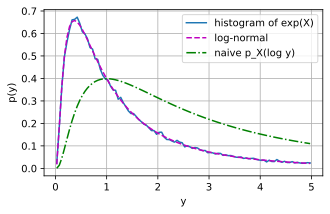

In [4]:
y = np.exp(rng.standard_normal(10**5))                 # Y = e^X
edges = np.linspace(0, 5, 101)
mids = (edges[:-1] + edges[1:]) / 2
hist = np.histogram(y, edges)[0] / (len(y) * (edges[1] - edges[0]))
p_X = lambda x: np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
d2l.plot(mids, [hist, p_X(np.log(mids)) / mids, p_X(np.log(mids))],
         'y', 'p(y)', figsize=(5, 3),
         legend=['histogram of exp(X)', 'log-normal', 'naive p_X(log y)'])

The histogram tracks the log-normal density closely up to sampling noise, with
its peak well to the left of $y=1$, near $e^{-1}$. The naive curve puts the
peak in the wrong place: because it equals the true density multiplied by $y$,
it falls below the data for $y<1$ and rises above it for $y>1$, by a factor
that keeps growing into the tail.

### The Multivariate Rule

In several dimensions, a transformation stretches areas and volumes rather than
lengths, so the stretch factor becomes a determinant. Start with the simplest
case, a linear map $\mathbf Y=\mathbf A\mathbf X$ with
$\mathbf A=\operatorname{diag}(2,3)$. This map turns a unit square into a
$2\times3$ rectangle of area $6=\det\mathbf A$. Because the rectangle must
carry the same probability as the original square, the density of $\mathbf Y$
must be one-sixth the density of $\mathbf X$ at the corresponding point:
$p_{\mathbf Y}(\mathbf y)=p_{\mathbf X}(\mathbf A^{-1}\mathbf y)/6$.

For a nonlinear map, the local stretch varies from point to point, and the
change-of-variables theorem for multiple integrals accounts for it
(that section). Let $g$ be a continuously differentiable
bijection between two regions of $\mathbb{R}^n$ with a continuously
differentiable inverse, and write $J_{g^{-1}}$ for the Jacobian matrix of
partial derivatives of the inverse. Locally, $g^{-1}$ scales volume by
$|\det J_{g^{-1}}|$, so substituting $\mathbf x=g^{-1}(\mathbf y)$ in an
integral over the preimage of a region $\mathcal D$ gives

$$
\int_{g^{-1}(\mathcal D)} f(\mathbf x)\,d\mathbf x=\int_{\mathcal D} f\bigl(g^{-1}(\mathbf y)\bigr)\,\bigl|\det J_{g^{-1}}(\mathbf y)\bigr|\,d\mathbf y .
$$

Now let $\mathbf Y=g(\mathbf X)$. The event $\mathbf Y\in\mathcal D$ is the
same as the event $\mathbf X\in g^{-1}(\mathcal D)$, so applying the theorem
with $f=p_{\mathbf X}$ yields

$$
P(\mathbf Y\in \mathcal D)=\int_{g^{-1}(\mathcal D)}p_{\mathbf X}(\mathbf x)\,d\mathbf x
=\int_{\mathcal D} p_{\mathbf X}\bigl(g^{-1}(\mathbf y)\bigr)\,\bigl|\det J_{g^{-1}}(\mathbf y)\bigr|\,d\mathbf y .
$$

The integrand on the right is therefore the density of $\mathbf Y$:

$$
\begin{aligned}
p_{\mathbf Y}(\mathbf y) &= p_{\mathbf X}\!\big(g^{-1}(\mathbf y)\big)\,\big|\det J_{g^{-1}}(\mathbf y)\big|, \\
\log p_{\mathbf Y}(\mathbf y) &= \log p_{\mathbf X}(\mathbf x) - \log\big|\det J_{g}(\mathbf x)\big| \\
&\quad\textrm{(equivalently, at }\mathbf x = g^{-1}(\mathbf y)\textrm{)}.
\end{aligned}
$$

The second line uses $J_{g^{-1}}(\mathbf y)=J_g(\mathbf x)^{-1}$. Passing a
sample through $g$ simply subtracts the log of the local volume stretch from
its log-density. Because $\log|\det(J_2 J_1)| = \log|\det J_1| + \log|\det J_2|$,
a composition of maps subtracts the sum of their log-determinants. This is the
exact mechanism by which *normalizing flows* compute exact likelihoods: they
stack invertible layers whose log-determinants are cheap to evaluate
[@rezende2015variational], and
that section builds one whose layers are the
steps of a differential equation.
Exercise 5 implements a coupling
layer from scratch.

Our dart provides one last illustration. Describe its position in polar
coordinates, the distance $R$ and the angle $\Theta$, via
$(x,y)=(r\cos\theta,r\sin\theta)$. The Jacobian determinant of this map from
$(r,\theta)$ to $(x,y)$ is
$\cos\theta\cdot r\cos\theta-(-r\sin\theta)\sin\theta=r$, so the multivariate
rule yields

$$
p_{R,\Theta}(r,\theta)=\frac1\pi\cdot r=2r\cdot\frac{1}{2\pi},
\qquad 0\le r\le1,\ 0\le\theta<2\pi .
$$

The joint density factorizes cleanly. The angle $\Theta$ is uniform on
$[0,2\pi)$, the distance $R$ recovers the density $2r$ once more (now straight
from a Jacobian), and the two variables are independent. In Cartesian
coordinates, the dart's $X$ and $Y$ were dependent; in the right coordinate
system, the exact same dart is described by two independent variables.

This section leaves one central question about averages open. We now know that
the average of $n$ independent draws has variance $\sigma^2/n$
the equation, but we do not yet know its distribution. Chebyshev's
inequality (that section) turns that variance into a
bound of $\sigma^2/(n\epsilon^2)$ on the probability that the average errs by
$\epsilon$ or more, yet for bounded or Gaussian draws this bound is far too
pessimistic: the true error probability drops exponentially fast in $n$. We
will determine which distribution an average approaches in
that section, and establish the exponential decay rate in
that section. Before tackling either,
however, we need a richer catalog of distributions than the dart alone.

## Summary

Marginal densities come from integrating out unneeded variables, and
conditional densities come from slicing the joint density along a thin strip
and renormalizing. The conditional mean is the optimal squared-error predictor,
and the law of total variance splits a variable's variance into the part that
the conditioning variable explains and the part it cannot. Covariance and
correlation measure linear association rather than general dependence, and
averaging $n$ independent draws with finite variance reduces the variance to
$\sigma^2/n$. Under a smooth invertible map, a density is divided by the local
volume stretch, given by the absolute Jacobian determinant. Our dart brings all
of these ideas together: its Cartesian coordinates are dependent yet
uncorrelated, while in polar coordinates they become two independent variables.

## Exercises

1. **Uncorrelated but dependent.** Whitening, for example with the
   principal components of that section, makes
   coordinates uncorrelated. The following pair has Gaussian coordinates
   and zero covariance. Let $X \sim \mathcal{N}(0, 1)$, let $S$ be a random
   sign independent of $X$ with $P(S = 1) = P(S = -1) = \tfrac12$, and let
   $Y = SX$.
    1. Show that $Y \sim \mathcal{N}(0, 1)$ by computing its c.d.f., and
       that $\textrm{Cov}(X, Y) = 0$.
    1. Compare $P(|X| \le 1, |Y| \le 1)$ with
       $P(|X| \le 1)\,P(|Y| \le 1)$. Are $X$ and $Y$ independent?
    1. Show that $X + Y$ has an atom at $0$, so that $X + Y$ is not
       Gaussian. With probability one the point $(X, Y)$ lies on one of the
       two lines $y = \pm x$, and a double integral over a line is zero,
       because a line has no area. Conclude that the pair $(X, Y)$ has no
       joint density, although each coordinate has one.

1. **Averaging correlated estimates.** The text derives
   $\textrm{Var}(\bar X_n) = \sigma^2/n$ for independent draws. Averages of
   dependent estimates behave differently.
    1. Let $Y_1, \ldots, Y_n$ each have variance $\sigma^2$, with
       correlation $\rho$ between every pair, as the predictions of $n$
       ensemble members trained on the same data might. Show that

       $$\textrm{Var}\Bigl(\frac1n\sum_{i=1}^n Y_i\Bigr) = \sigma^2\Bigl(\rho + \frac{1-\rho}{n}\Bigr).$$

       What does averaging achieve as $n \to \infty$?
    1. Use $\mathbf{a}^\top \boldsymbol\Sigma\, \mathbf{a} \ge 0$ for the
       covariance matrix $\boldsymbol\Sigma$ of $Y_1, \ldots, Y_n$ to show
       that $\rho \ge -1/(n-1)$. Give variables that attain this bound.

1. [code] **Sigmoid of a Gaussian.** Let $X \sim \mathcal{N}(0, s^2)$ be
   the pre-activation of a sigmoid unit, and let
   $Y = \operatorname{sigmoid}(X)$, whose inverse is
   $\operatorname{logit}(y) = \log\bigl(y/(1-y)\bigr)$.
    1. Use the equation to find the density $p_Y$ on
       $(0, 1)$.
    1. For which $s$ is $y = \tfrac12$ a local minimum of $p_Y$? Writing
       $\log p_Y$ as a function of $z = \operatorname{logit}(y)$ simplifies
       the computation.
    1. Modify the `#random-variables-change-of-variables` cell to compare a
       histogram of $Y$ with $p_Y$ for $s \in \{1, \sqrt{2}, 3\}$. What does
       the histogram at $s = 3$ imply for the derivative
       $\operatorname{sigmoid}'(X) = Y(1 - Y)$, through which
       backpropagation passes the gradient of these units?

1. **Explained variance.** ● A regression model $h$ predicts a target $X$
   from an input $Y$. The fraction of the variance that it explains is
   $R^2 = 1 - \mathbb{E}\bigl[(X - h(Y))^2\bigr]/\textrm{Var}(X)$.
    1. Use the equation and the law of total variance
       the equation to show that every predictor has
       $R^2 \le \textrm{Var}\bigl(\mathbb{E}[X \mid Y]\bigr)/\textrm{Var}(X)$.
       Evaluate this ceiling for the two-component mixture of the text,
       predicting $X$ from the label $Z$, and for the dart, predicting $X$
       from $Y$.
    1. Given the input, the target is $-1$ or $+1$ with probability
       $\tfrac12$ each. Which prediction minimizes the expected squared
       error, and how often does the target take that value? Which
       predictions minimize the expected absolute error
       $\mathbb{E}\bigl[|X - h(Y)|\bigr]$?

1. [code] **Affine coupling layer and Box--Muller.** ● Normalizing flows
   stack invertible maps whose log-determinants in
   the equation are cheap to compute. The affine coupling
   layer of RealNVP [@dinh2017density] maps $\mathbf{x} \in
   \mathbb{R}^2$ to

   $$y_1 = x_1, \qquad y_2 = x_2\, e^{s(x_1)} + t(x_1),$$

   where $s$ and $t$ are arbitrary functions, for example small neural
   networks.
    1. Write down the inverse map and the Jacobian $J_g(\mathbf{x})$. Show
       that $\log|\det J_g(\mathbf{x})| = s(x_1)$, however complicated $s$
       and $t$ are.
    1. Let $X_1$ and $X_2$ be independent standard normal variables, and
       take $s(x_1) = \tanh(x_1)$ and $t(x_1) = x_1^2/2$. Use
       the equation to write $\log p_{\mathbf{Y}}(\mathbf{y})$
       in closed form. With NumPy, evaluate $p_{\mathbf{Y}}$ on a grid over
       $[-6, 6] \times [-12, 24]$ with spacing $0.02$ and check that its
       Riemann sum is close to $1$. Check the log-determinant against the
       determinant of a finite-difference Jacobian at a few random points.
    1. The first coordinate passes through the layer unchanged. What is the
       distribution of $Y_1$, whatever $s$ and $t$ are? How must a second
       coupling layer be arranged so that the composition can change both
       marginals, and what is the log-determinant of the composition?
    1. Flows can also run from uniform noise to Gaussians. Let $U_1, U_2$
       be independent and uniform on $(0, 1)$, and set
       $R = \sqrt{-2\log U_1}$, $\Theta = 2\pi U_2$, and
       $(Z_1, Z_2) = (R\cos\Theta, R\sin\Theta)$. Find the density of $R$
       with the one-dimensional rule, then the joint density of
       $(R, \Theta)$, and change to Cartesian coordinates with the polar
       Jacobian of the text to show that $Z_1$ and $Z_2$ are independent
       standard normal variables. This is the Box--Muller method. Check
       with $10^5$ samples that the sample covariance matrix of
       $(Z_1, Z_2)$ is close to the identity.

[Discussions](https://d2l.discourse.group/t/36880)